# CampusPulse — Advanced Data Analytics
### `03_analytics.ipynb` · EDA + Correlation + Dimensionality Reduction + Clustering

---

**What this notebook does:**  
Goes beyond basic cleaning to extract real analytical insight from the data using statistical and machine-learning techniques.

**Techniques covered:**

| Section | Technique | Purpose |
|---------|-----------|---------|
| 1 | Correlation Analysis | Understand linear relationships between features |
| 2 | Distribution Deep Dive | Understand how features differ across stress groups |
| 3 | Outlier Detection | Find and reason about extreme values |
| 4 | PCA | Reduce dimensions, find dominant patterns |
| 5 | t-SNE | Non-linear 2D embedding, reveal cluster structure |
| 6 | Mutual Information | Feature importance without a model |
| 7 | K-Means Clustering | Find natural student groups |
| 8 | Cross-Dataset Comparison | Compare populations using only valid relative metrics |


## 0 · Imports and Data Loading

> All three clean datasets are loaded here. Each is used independently for dataset-specific analyses (Sections 1–7). Section 8 uses the standardized table which you must build with `03_standardize.ipynb`, or it is constructed inline here for the cross-dataset plots.


In [2]:
import os
from pathlib import Path
import warnings

# Resolve the project root so relative data paths work from either the root or src/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Could not locate the project data/raw directory")
os.chdir(PROJECT_ROOT)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import pointbiserialr, chi2_contingency
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.feature_selection import mutual_info_classif
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Plotting style
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor":   "#f8f9fa",
    "axes.grid":        True,
    "grid.color":       "white",
    "grid.linewidth":   1.0,
    "font.size":        11,
})
PALETTE = {"Low": "#34d399", "Moderate": "#fbbf24", "High": "#f87171"}
DS_PALETTE = {"lifestyle": "#6c8ef7", "uci": "#a78bfa", "mental_health": "#f97316"}

Path("data/analytics").mkdir(parents=True, exist_ok=True)

# ── Load clean datasets ──────────────────────────────────────────────────────
df_ls = pd.read_csv("data/processed/lifestyle_clean.csv")
df_uc = pd.read_csv("data/processed/uci_clean.csv")
df_mh = pd.read_csv("data/processed/mental_health_clean.csv")

print(f"Lifestyle:    {df_ls.shape}")
print(f"UCI:          {df_uc.shape}")
print(f"Mental Health:{df_mh.shape}")


Lifestyle:    (2000, 7)
UCI:          (1044, 37)
Mental Health:(100, 13)


In [4]:
# Define feature sets for each dataset (only numeric analytical columns)
LS_FEATURES  = ["study_hours_per_day", "sleep_hours_per_day",
                 "extracurricular_hours_per_day", "social_hours_per_day",
                 "physical_activity_hours_per_day", "gpa"]

UCI_FEATURES = ["age", "studytime", "failures", "absences",
                 "g1", "g2", "g3", "dalc", "walc",
                 "famrel", "freetime", "goout", "health"]

MH_FEATURES  = ["age", "cgpa_midpoint", "depression",
                 "anxiety", "panic_attack", "stress_score"]

print("Feature sets defined:")
print(f"  Lifestyle:    {LS_FEATURES}")
print(f"  UCI:          {UCI_FEATURES}")
print(f"  Mental Health:{MH_FEATURES}")


Feature sets defined:
  Lifestyle:    ['study_hours_per_day', 'sleep_hours_per_day', 'extracurricular_hours_per_day', 'social_hours_per_day', 'physical_activity_hours_per_day', 'gpa']
  UCI:          ['age', 'studytime', 'failures', 'absences', 'g1', 'g2', 'g3', 'dalc', 'walc', 'famrel', 'freetime', 'goout', 'health']
  Mental Health:['age', 'cgpa_midpoint', 'depression', 'anxiety', 'panic_attack', 'stress_score']


---
## 1 · Correlation Analysis

**What is correlation?**  
Correlation measures whether two variables tend to move together (positive) or in opposite directions (negative).  
- Value near **+1**: strong positive relationship  
- Value near **−1**: strong negative relationship  
- Value near **0**: no linear relationship  

**Why it matters for data analytics:**  
1. Identifies which features are related to the target (stress, GPA)  
2. Detects **multicollinearity** — when two features carry near-identical information (e.g. G1 and G2 in UCI). Knowing this prevents you from using both in a model and overcounting the same signal.  
3. Guides feature selection before clustering or PCA.

**Which correlation coefficient to use:**  
| Data types | Coefficient |
|---|---|
| Continuous ↔ Continuous | Pearson's r |
| Continuous ↔ Binary (0/1) | Point-Biserial (mathematically equivalent to Pearson) |
| Ordinal ↔ Ordinal | Spearman's ρ |


### 1.1 · Lifestyle Dataset — Correlation Heatmap

> **Encoding stress for correlation:** `stress_level` is categorical (Low/Moderate/High). We encode it as 0/1/2 to include it in the correlation matrix. This is called **ordinal encoding** — valid here because the stress levels have a natural order.


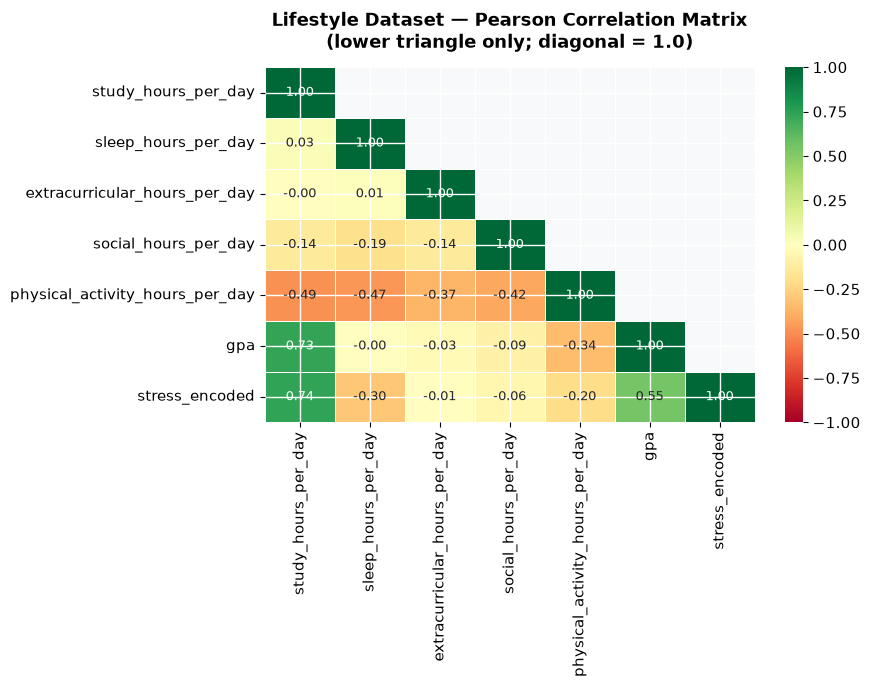

In [5]:
# Ordinal encode stress level for correlation
stress_ord = {"Low": 0, "Moderate": 1, "High": 2}
df_ls_corr = df_ls[LS_FEATURES].copy()
df_ls_corr["stress_encoded"] = df_ls["stress_level"].map(stress_ord)

# Compute Pearson correlation matrix
corr_ls = df_ls_corr.corr(method="pearson").round(3)

# ── Plot heatmap ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))

mask = np.triu(np.ones_like(corr_ls, dtype=bool), k=1)   # hide upper triangle (redundant)

sns.heatmap(
    corr_ls,
    mask=mask,
    annot=True, fmt=".2f",
    cmap="RdYlGn",
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor="white",
    annot_kws={"size": 9},
    ax=ax
)
ax.set_title("Lifestyle Dataset — Pearson Correlation Matrix\n(lower triangle only; diagonal = 1.0)",
             fontsize=13, fontweight="bold", pad=14)
plt.tight_layout()
plt.savefig("data/analytics/ls_correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


In [6]:
# ── Print the strongest correlations with stress ──────────────────────────
print("=== Top correlations with stress_encoded ===")
stress_corr = corr_ls["stress_encoded"].drop("stress_encoded").abs().sort_values(ascending=False)
for feat, val in stress_corr.items():
    direction = "↑" if corr_ls.loc[feat, "stress_encoded"] > 0 else "↓"
    print(f"  {feat:<38} r = {corr_ls.loc[feat,'stress_encoded']:+.3f}  {direction}")

print("\n=== Top correlations with GPA ===")
gpa_corr = corr_ls["gpa"].drop("gpa").abs().sort_values(ascending=False)
for feat, val in gpa_corr.items():
    direction = "↑" if corr_ls.loc[feat, "gpa"] > 0 else "↓"
    print(f"  {feat:<38} r = {corr_ls.loc[feat,'gpa']:+.3f}  {direction}")

print("\n💡 Interpretation guide:")
print("  |r| > 0.5  → strong relationship")
print("  |r| 0.3–0.5 → moderate")
print("  |r| < 0.3  → weak (may still be significant with n=2000)")


=== Top correlations with stress_encoded ===
  study_hours_per_day                    r = +0.739  ↑
  gpa                                    r = +0.550  ↑
  sleep_hours_per_day                    r = -0.299  ↓
  physical_activity_hours_per_day        r = -0.205  ↓
  social_hours_per_day                   r = -0.055  ↓
  extracurricular_hours_per_day          r = -0.006  ↓

=== Top correlations with GPA ===
  study_hours_per_day                    r = +0.734  ↑
  stress_encoded                         r = +0.550  ↑
  physical_activity_hours_per_day        r = -0.341  ↓
  social_hours_per_day                   r = -0.086  ↓
  extracurricular_hours_per_day          r = -0.032  ↓
  sleep_hours_per_day                    r = -0.004  ↓

💡 Interpretation guide:
  |r| > 0.5  → strong relationship
  |r| 0.3–0.5 → moderate
  |r| < 0.3  → weak (may still be significant with n=2000)


### 1.2 · UCI Dataset — Grade Multicollinearity

> **Multicollinearity** occurs when two or more features are highly correlated with each other (not just with the target). In the UCI dataset, G1, G2, G3 are grades from three consecutive assessment periods — they should be very highly correlated. If you include all three in a model, you are effectively triple-counting the same information.

> **What to do about it:** For predictive models, drop G1 and G2 and keep only G3 (the final grade). For exploratory analysis, all three can be kept. For PCA, multicollinear features get absorbed into the same principal component.


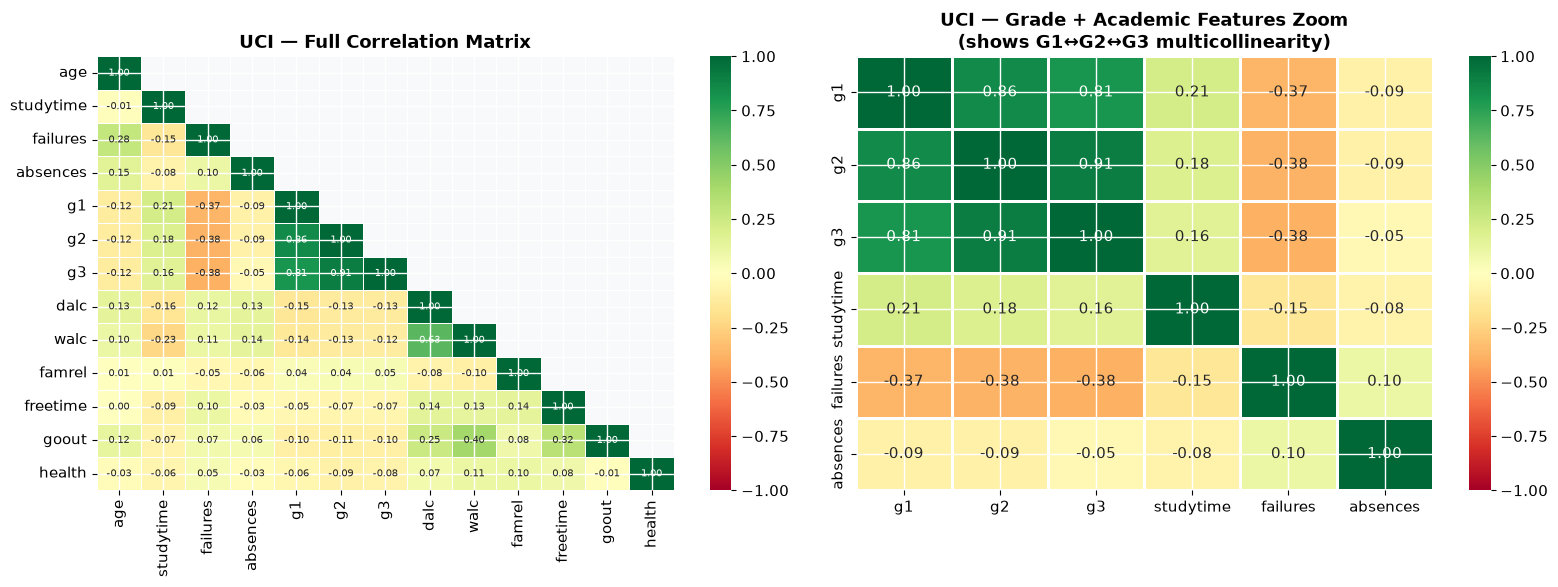

G1↔G3 correlation: r = 0.809
G2↔G3 correlation: r = 0.911
G1↔G2 correlation: r = 0.859

→ G1, G2, G3 are highly multicollinear. For modelling, use G3 only.


In [7]:
df_uc_corr = df_uc[UCI_FEATURES].copy()
corr_uc = df_uc_corr.corr(method="pearson").round(3)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Full heatmap
mask_uc = np.triu(np.ones_like(corr_uc, dtype=bool), k=1)
sns.heatmap(corr_uc, mask=mask_uc, annot=True, fmt=".2f",
            cmap="RdYlGn", center=0, vmin=-1, vmax=1,
            linewidths=0.4, linecolor="white", annot_kws={"size": 7.5},
            ax=axes[0])
axes[0].set_title("UCI — Full Correlation Matrix", fontweight="bold")

# Zoom: grade intercorrelation
grade_cols = ["g1", "g2", "g3", "studytime", "failures", "absences"]
corr_grades = df_uc[grade_cols].corr()
sns.heatmap(corr_grades, annot=True, fmt=".2f",
            cmap="RdYlGn", center=0, vmin=-1, vmax=1,
            linewidths=1.0, linecolor="white", annot_kws={"size": 11},
            ax=axes[1])
axes[1].set_title("UCI — Grade + Academic Features Zoom\n(shows G1↔G2↔G3 multicollinearity)",
                  fontweight="bold")

plt.tight_layout()
plt.savefig("data/analytics/uci_correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"G1↔G3 correlation: r = {corr_uc.loc['g1','g3']:.3f}")
print(f"G2↔G3 correlation: r = {corr_uc.loc['g2','g3']:.3f}")
print(f"G1↔G2 correlation: r = {corr_uc.loc['g1','g2']:.3f}")
print("\n→ G1, G2, G3 are highly multicollinear. For modelling, use G3 only.")


### 1.3 · Mental Health — Point-Biserial Correlations

> The mental health dataset has mostly binary (0/1) columns. The correct coefficient for correlating a **binary variable with a continuous variable** is the **point-biserial correlation** (rpb). Mathematically it is identical to Pearson's r, but the name signals that one variable is binary — it's an important distinction to state in a report.


In [8]:
from scipy.stats import pointbiserialr

continuous_mh = ["age", "cgpa_midpoint"]
binary_mh     = ["depression", "anxiety", "panic_attack", "sought_treatment"]

print("=== Point-Biserial Correlations (continuous vs binary) ===\n")
results = []
for cont in continuous_mh:
    for binar in binary_mh:
        valid = df_mh[[cont, binar]].dropna()
        r, p = pointbiserialr(valid[binar], valid[cont])
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        results.append({"Continuous": cont, "Binary": binar,
                        "r_pb": round(r, 3), "p-value": round(p, 4), "sig": sig})
        print(f"  {cont:<15} ↔ {binar:<20}  r_pb={r:+.3f}  p={p:.4f}  {sig}")

print("\n  Significance: *** p<0.001  ** p<0.01  * p<0.05  ns=not significant")
print("\n=== Binary ↔ Binary (Phi coefficient via Chi-Square) ===\n")

for i, b1 in enumerate(binary_mh):
    for b2 in binary_mh[i+1:]:
        valid = df_mh[[b1, b2]].dropna()
        ct = pd.crosstab(valid[b1], valid[b2])
        chi2, p, dof, _ = chi2_contingency(ct)
        phi = np.sqrt(chi2 / len(valid))   # Phi = effect size for 2×2 tables
        sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
        print(f"  {b1:<20} ↔ {b2:<20}  φ={phi:.3f}  p={p:.4f}  {sig}")


=== Point-Biserial Correlations (continuous vs binary) ===

  age             ↔ depression            r_pb=-0.072  p=0.4755  ns
  age             ↔ anxiety               r_pb=-0.094  p=0.3540  ns
  age             ↔ panic_attack          r_pb=+0.056  p=0.5817  ns
  age             ↔ sought_treatment      r_pb=+0.048  p=0.6367  ns
  cgpa_midpoint   ↔ depression            r_pb=+0.013  p=0.8942  ns
  cgpa_midpoint   ↔ anxiety               r_pb=+0.158  p=0.1164  ns
  cgpa_midpoint   ↔ panic_attack          r_pb=+0.016  p=0.8773  ns
  cgpa_midpoint   ↔ sought_treatment      r_pb=+0.017  p=0.8700  ns

  Significance: *** p<0.001  ** p<0.01  * p<0.05  ns=not significant

=== Binary ↔ Binary (Phi coefficient via Chi-Square) ===

  depression           ↔ anxiety               φ=0.248  p=0.0132  *
  depression           ↔ panic_attack          φ=0.221  p=0.0273  *
  depression           ↔ sought_treatment      φ=0.300  p=0.0027  **
  anxiety              ↔ panic_attack          φ=0.057  p=0.56

---
## 2 · Distribution Deep Dive — Features by Stress Group

**Why look at distributions per group?**  
A mean alone hides the shape. Two groups can have the same mean but completely different spreads (variance), skew (asymmetry), or bimodality. Violin plots show the full distribution shape; KDE (Kernel Density Estimation) overlays let you compare groups directly.

**KDE explained:** A KDE curve is a smoothed version of a histogram — instead of discrete bins, it estimates a continuous probability density. The area under any KDE curve is 1. When two KDE curves overlap heavily, the groups are hard to distinguish on that feature. When they are well-separated, that feature is a strong discriminator.


### 2.1 · Lifestyle — Violin Plots per Stress Level

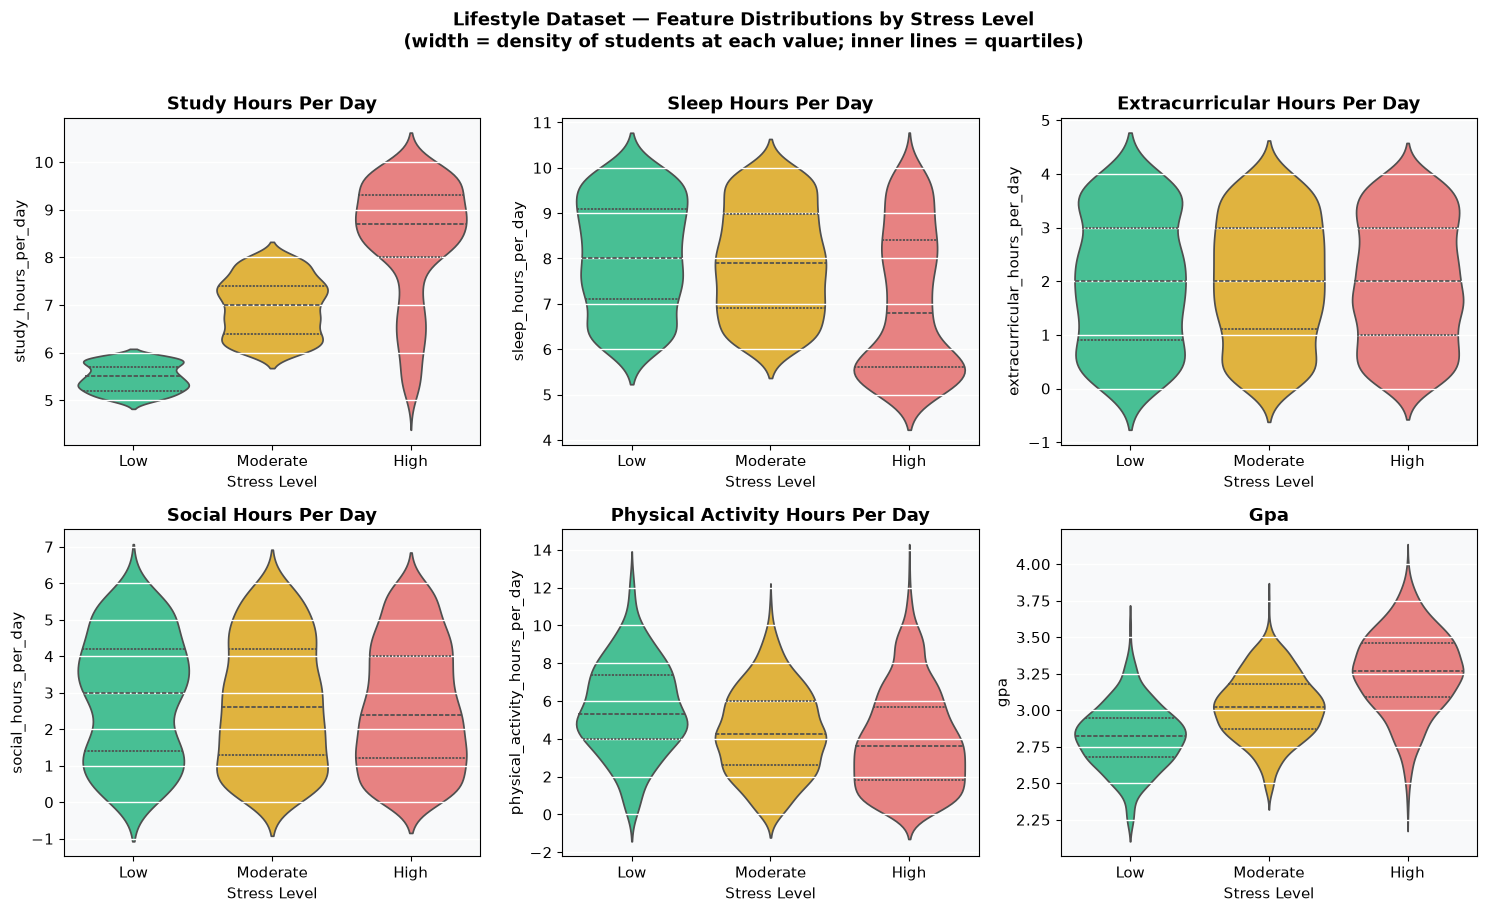

In [9]:
order = ["Low", "Moderate", "High"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feat in enumerate(LS_FEATURES):
    ax = axes[i]
    sns.violinplot(
        data=df_ls, x="stress_level", y=feat,
        order=order, palette=PALETTE,
        inner="quartile",   # show median + IQR inside violin
        ax=ax
    )
    ax.set_title(feat.replace("_", " ").title(), fontweight="bold")
    ax.set_xlabel("Stress Level")

plt.suptitle("Lifestyle Dataset — Feature Distributions by Stress Level\n"
             "(width = density of students at each value; inner lines = quartiles)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("data/analytics/ls_violin_by_stress.png", dpi=130, bbox_inches="tight")
plt.show()


### 2.2 · Lifestyle — KDE Overlays (Study Hours & GPA)

> KDE overlays are particularly useful for seeing **whether stress groups form separable clusters** on a single feature — a prerequisite for classification to work well.


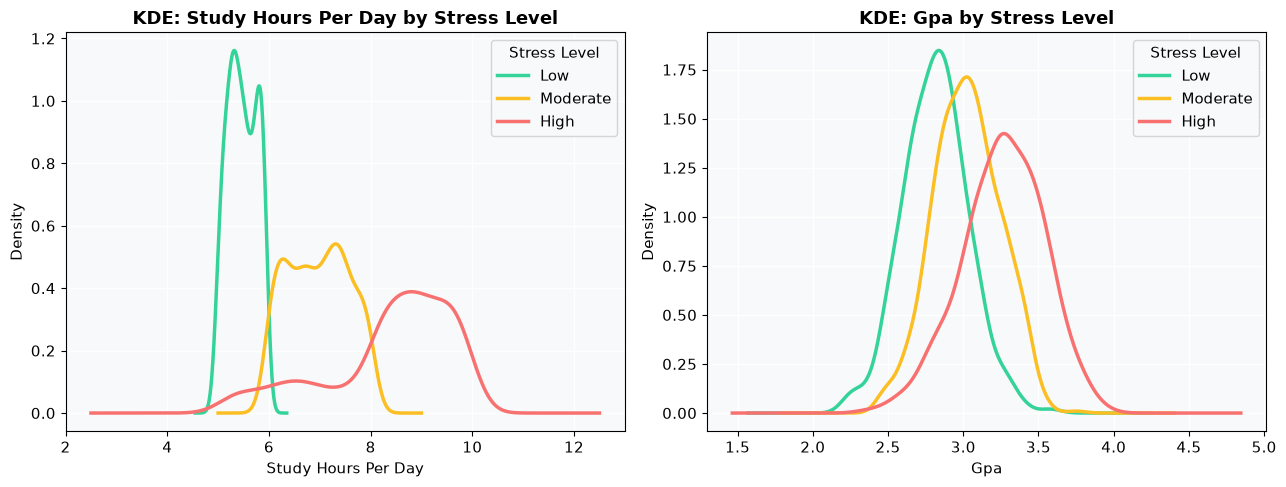

Interpretation:
  → Overlapping KDE curves = feature does NOT separate stress groups well
  → Separated KDE peaks   = feature IS a useful discriminator


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feat in zip(axes, ["study_hours_per_day", "gpa"]):
    for level in ["Low", "Moderate", "High"]:
        subset = df_ls[df_ls["stress_level"] == level][feat].dropna()
        subset.plot.kde(ax=ax, label=level, color=PALETTE[level], linewidth=2.5)
    ax.set_title(f"KDE: {feat.replace('_',' ').title()} by Stress Level",
                 fontweight="bold")
    ax.set_xlabel(feat.replace("_", " ").title())
    ax.set_ylabel("Density")
    ax.legend(title="Stress Level")

plt.tight_layout()
plt.savefig("data/analytics/ls_kde_study_gpa.png", dpi=130, bbox_inches="tight")
plt.show()

print("Interpretation:")
print("  → Overlapping KDE curves = feature does NOT separate stress groups well")
print("  → Separated KDE peaks   = feature IS a useful discriminator")


### 2.3 · UCI — Grade Progression G1 → G2 → G3

> Tracking G1 → G2 → G3 shows whether student performance **trends up, down, or is stable** across the school year. This kind of longitudinal within-student comparison is only possible because UCI has three time-point grades.


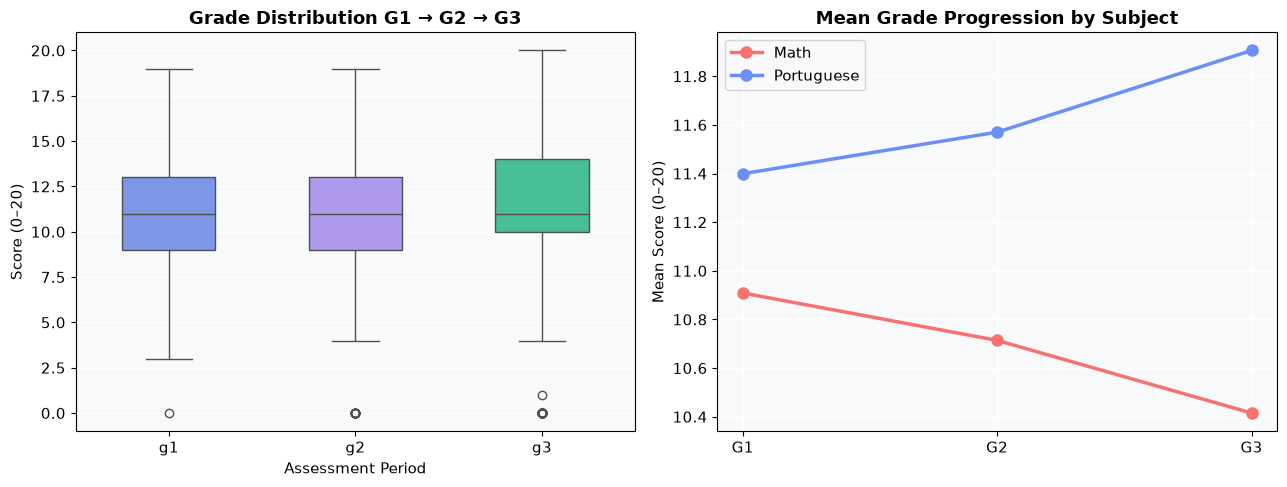

Mean grade change G1→G3: +0.128
Students who improved (G3 > G1): 487
Students who declined (G3 < G1): 279


In [11]:
# Melt to long format for easy plotting
df_grades_long = df_uc[["g1", "g2", "g3", "subject"]].melt(
    id_vars="subject", var_name="period", value_name="grade"
)
period_order = ["g1", "g2", "g3"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Box plot of grade distribution per period
sns.boxplot(data=df_grades_long, x="period", y="grade",
            order=period_order, palette=["#6c8ef7","#a78bfa","#34d399"],
            width=0.5, ax=axes[0])
axes[0].set_title("Grade Distribution G1 → G2 → G3", fontweight="bold")
axes[0].set_xlabel("Assessment Period")
axes[0].set_ylabel("Score (0–20)")

# Mean grade per period, split by subject
for subj, color in zip(["math", "portuguese"], ["#f87171", "#6c8ef7"]):
    means = [df_uc[df_uc["subject"]==subj][g].mean() for g in ["g1","g2","g3"]]
    axes[1].plot(["G1","G2","G3"], means, marker="o", label=subj.title(),
                 color=color, linewidth=2.5, markersize=8)
axes[1].set_title("Mean Grade Progression by Subject", fontweight="bold")
axes[1].set_ylabel("Mean Score (0–20)")
axes[1].legend()

plt.tight_layout()
plt.savefig("data/analytics/uci_grade_progression.png", dpi=130, bbox_inches="tight")
plt.show()

# Compute grade change stats
df_uc["g3_minus_g1"] = df_uc["g3"] - df_uc["g1"]
print(f"Mean grade change G1→G3: {df_uc['g3_minus_g1'].mean():+.3f}")
print(f"Students who improved (G3 > G1): {(df_uc['g3_minus_g1'] > 0).sum()}")
print(f"Students who declined (G3 < G1): {(df_uc['g3_minus_g1'] < 0).sum()}")


---
## 3 · Outlier Detection

**What is an outlier?**  
A data point that is unusually far from the rest of the distribution. Outliers can be:
- **Genuine** — a student who really does study 18 hours/day (unusual but real)  
- **Erroneous** — a data entry mistake like a GPA of 9.5  
- **Informative** — a student with zero social hours and maximum GPA (a real pattern worth studying)

**IQR Method (the standard approach):**  
- Q1 = 25th percentile, Q3 = 75th percentile  
- IQR = Q3 − Q1 (the middle 50% of data)  
- Outlier boundary: below Q1 − 1.5×IQR or above Q3 + 1.5×IQR  
- The factor 1.5 is a convention (Tukey 1977) — use 3.0 for *extreme* outliers only  

**What to do after finding outliers:** Don't blindly remove them. Investigate first. Ask: is this a real student who exists at the extreme of a distribution, or a data quality issue?


In [12]:
def detect_outliers_iqr(df, cols, factor=1.5):
    """
    Detect outliers using the IQR method for each column.
    Returns a summary DataFrame showing outlier counts and bounds.
    """
    results = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo  = q1 - factor * iqr
        hi  = q3 + factor * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        pct   = n_out / len(s) * 100
        results.append({
            "feature": col,
            "Q1": round(q1,3), "Q3": round(q3,3), "IQR": round(iqr,3),
            "lower_fence": round(lo,3), "upper_fence": round(hi,3),
            "n_outliers": n_out, "pct_outliers": round(pct,2)
        })
    return pd.DataFrame(results)

print("=== Lifestyle Dataset — Outlier Summary ===")
ls_outliers = detect_outliers_iqr(df_ls, LS_FEATURES)
print(ls_outliers.to_string(index=False))


=== Lifestyle Dataset — Outlier Summary ===
                        feature  Q1   Q3  IQR  lower_fence  upper_fence  n_outliers  pct_outliers
            study_hours_per_day 6.3 8.70 2.40        2.700       12.300           0          0.00
            sleep_hours_per_day 6.2 8.80 2.60        2.300       12.700           0          0.00
  extracurricular_hours_per_day 1.0 3.00 2.00       -2.000        6.000           0          0.00
           social_hours_per_day 1.2 4.10 2.90       -3.150        8.450           0          0.00
physical_activity_hours_per_day 2.4 6.10 3.70       -3.150       11.650           5          0.25
                            gpa 2.9 3.33 0.43        2.255        3.975           4          0.20


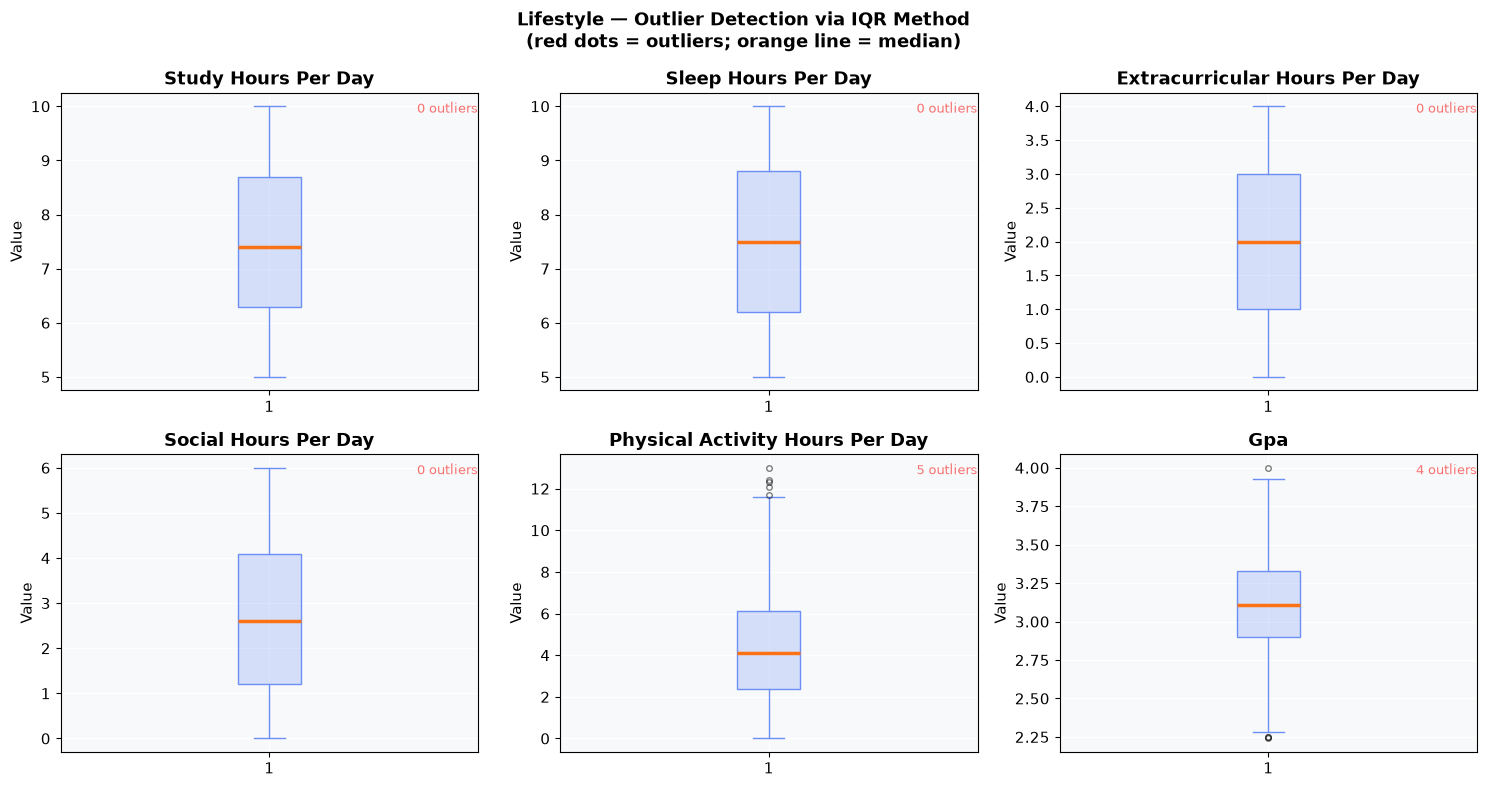

In [13]:
# Box plots with outlier dots highlighted
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feat in enumerate(LS_FEATURES):
    ax = axes[i]
    ax.boxplot(df_ls[feat].dropna(),
               vert=True, patch_artist=True,
               boxprops=dict(facecolor="#6c8ef740", color="#6c8ef7"),
               medianprops=dict(color="#f97316", linewidth=2.5),
               flierprops=dict(marker="o", color="#f87171",
                               alpha=0.5, markersize=4),
               whiskerprops=dict(color="#6c8ef7"),
               capprops=dict(color="#6c8ef7"))
    ax.set_title(feat.replace("_"," ").title(), fontweight="bold")
    ax.set_ylabel("Value")
    # Annotate outlier count
    n_out = ls_outliers[ls_outliers["feature"]==feat]["n_outliers"].values[0]
    ax.annotate(f"{n_out} outliers", xy=(1.0, 0.97),
                xycoords="axes fraction", ha="right", va="top",
                fontsize=9, color="#f87171")

plt.suptitle("Lifestyle — Outlier Detection via IQR Method\n"
             "(red dots = outliers; orange line = median)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("data/analytics/ls_outlier_boxplots.png", dpi=130, bbox_inches="tight")
plt.show()


In [14]:
# Z-score method — complementary approach
from scipy.stats import zscore

print("=== Z-score Outliers (|z| > 3) — Lifestyle ===")
z_scores = df_ls[LS_FEATURES].apply(zscore)
extreme = (z_scores.abs() > 3).sum()
print(extreme.to_string())
print("\nZ-score method uses standard deviations from the mean.")
print("Anything beyond ±3σ covers 99.7% of a normal distribution.")
print("More sensitive than IQR for normally-distributed features.")


=== Z-score Outliers (|z| > 3) — Lifestyle ===
study_hours_per_day                0
sleep_hours_per_day                0
extracurricular_hours_per_day      0
social_hours_per_day               0
physical_activity_hours_per_day    4
gpa                                0

Z-score method uses standard deviations from the mean.
Anything beyond ±3σ covers 99.7% of a normal distribution.
More sensitive than IQR for normally-distributed features.


---
## 4 · Principal Component Analysis (PCA)

**What PCA does:**  
PCA finds the directions (principal components) in the data along which the **variance is maximized**. It rotates the feature space so that PC1 captures the most variation, PC2 the second most, and so on — with each PC orthogonal (uncorrelated) to the previous.

**Why it is useful here:**  
- With 6 lifestyle features, it is hard to visualize the data. PCA projects it into 2D while retaining as much variance as possible.  
- The **scree plot** shows how many components are needed to capture most of the information.  
- The **biplot** shows which original features are driving each component — this gives semantic meaning to the PCs.  
- Features that load heavily on the same PC are telling similar stories (potential multicollinearity).

**Critical prerequisite:** Features must be **standardized** (z-scored) before PCA. If you skip this, PCA will be dominated by whichever feature has the largest numerical scale — not the most informative feature.


### 4.1 · PCA on Lifestyle Dataset

In [15]:
# ── Standardize features (z-score: mean=0, std=1) ───────────────────────────
X_ls = df_ls[LS_FEATURES].dropna()
scaler_ls = StandardScaler()
X_ls_scaled = scaler_ls.fit_transform(X_ls)

print(f"Input shape: {X_ls_scaled.shape}")
print(f"Mean of scaled data (should be ~0): {X_ls_scaled.mean(axis=0).round(4)}")
print(f"Std  of scaled data (should be ~1): {X_ls_scaled.std(axis=0).round(4)}")


Input shape: (2000, 6)
Mean of scaled data (should be ~0): [-0.  0.  0. -0. -0.  0.]
Std  of scaled data (should be ~1): [1. 1. 1. 1. 1. 1.]


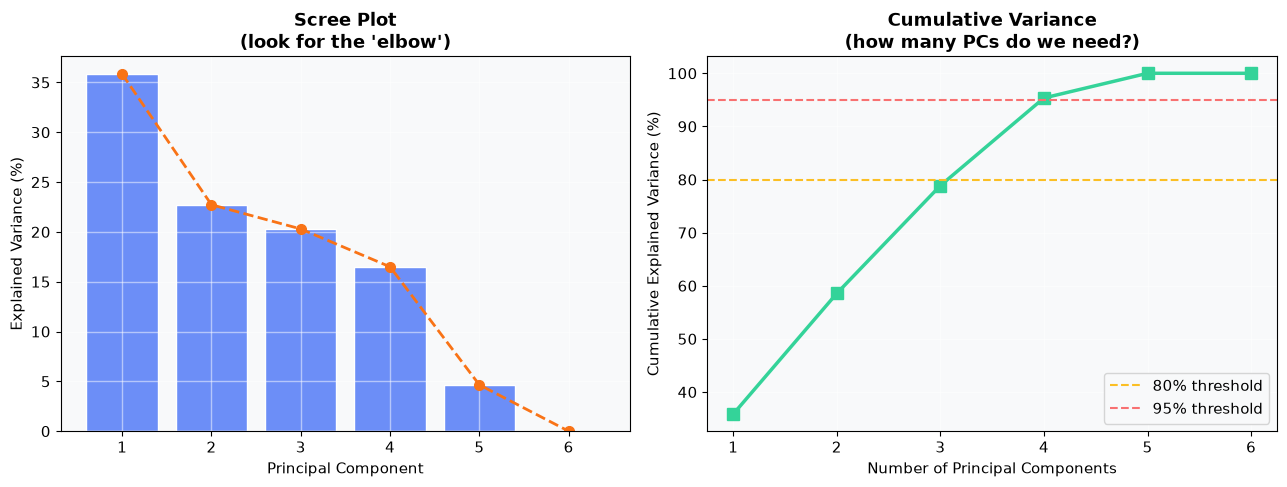

  PC1:  35.8% variance  |  cumulative:  35.8%
  PC2:  22.7% variance  |  cumulative:  58.6%
  PC3:  20.3% variance  |  cumulative:  78.9%
  PC4:  16.5% variance  |  cumulative:  95.4%
  PC5:   4.6% variance  |  cumulative: 100.0%
  PC6:   0.0% variance  |  cumulative: 100.0%


In [16]:
# ── Fit full PCA (all components) ────────────────────────────────────────────
pca_ls_full = PCA()
pca_ls_full.fit(X_ls_scaled)

explained_var    = pca_ls_full.explained_variance_ratio_
cumulative_var   = np.cumsum(explained_var)
n_components_all = len(explained_var)

# ── Scree Plot + Cumulative Variance ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot (individual explained variance)
axes[0].bar(range(1, n_components_all+1), explained_var * 100,
            color="#6c8ef7", edgecolor="white", label="Individual")
axes[0].plot(range(1, n_components_all+1), explained_var * 100,
             "o--", color="#f97316", linewidth=2, markersize=7)
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance (%)")
axes[0].set_title("Scree Plot\n(look for the 'elbow')", fontweight="bold")
axes[0].set_xticks(range(1, n_components_all+1))

# Cumulative variance
axes[1].plot(range(1, n_components_all+1), cumulative_var * 100,
             "s-", color="#34d399", linewidth=2.5, markersize=8)
axes[1].axhline(80, color="#fbbf24", linestyle="--", linewidth=1.5, label="80% threshold")
axes[1].axhline(95, color="#f87171", linestyle="--", linewidth=1.5, label="95% threshold")
axes[1].set_xlabel("Number of Principal Components")
axes[1].set_ylabel("Cumulative Explained Variance (%)")
axes[1].set_title("Cumulative Variance\n(how many PCs do we need?)", fontweight="bold")
axes[1].legend()
axes[1].set_xticks(range(1, n_components_all+1))

for ax in axes:
    ax.grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig("data/analytics/ls_pca_scree.png", dpi=130, bbox_inches="tight")
plt.show()

for i, (ev, cv) in enumerate(zip(explained_var, cumulative_var)):
    print(f"  PC{i+1}: {ev*100:5.1f}% variance  |  cumulative: {cv*100:5.1f}%")


### 4.2 · PCA Biplot — What Does Each PC Represent?

> A **biplot** overlays two things:  
> 1. The **scores** — each student projected onto PC1/PC2 (the scatter points)  
> 2. The **loadings** — arrows showing how original features contribute to each PC  

> How to read arrows:  
> - **Arrow length** → how much this feature contributes to variance in this 2D view  
> - **Arrow direction** → features pointing in the same direction are positively correlated; opposite = negatively correlated  
> - **Arrow angle to axis** → a horizontal arrow loads primarily on PC1; a vertical arrow on PC2


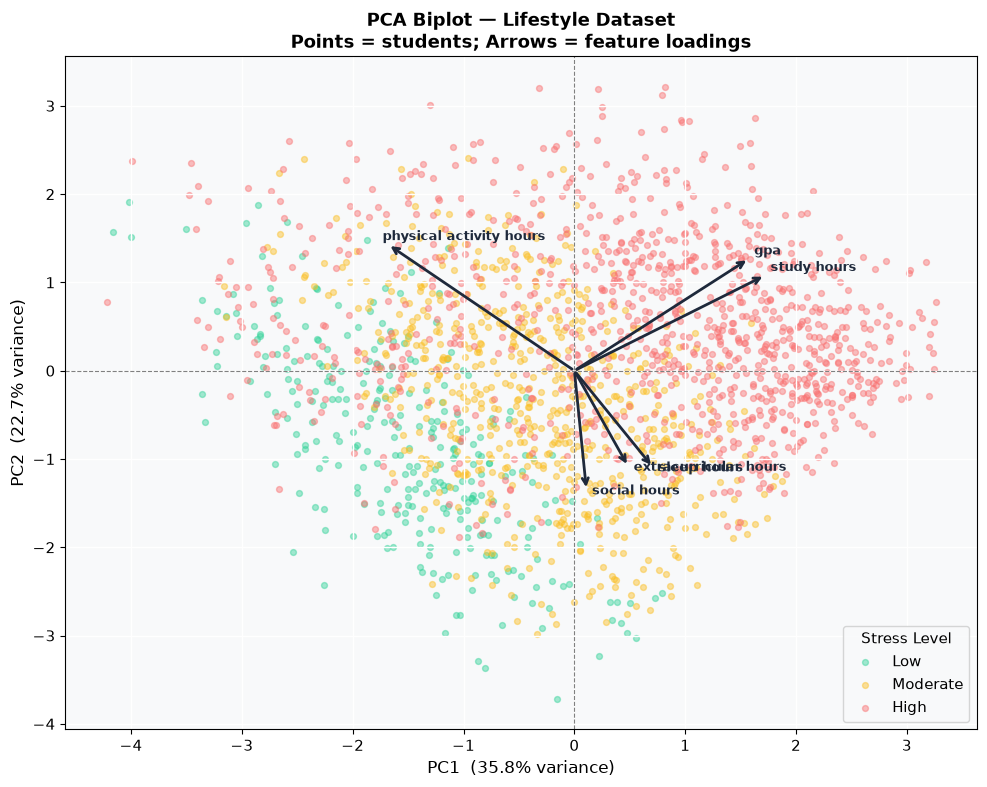

=== PC1 Loadings (what drives the first principal component?) ===
  study_hours_per_day                      +0.573  ████████
  physical_activity_hours_per_day          -0.560  ████████
  gpa                                      +0.524  ███████
  sleep_hours_per_day                      +0.236  ███
  extracurricular_hours_per_day            +0.162  ██
  social_hours_per_day                     +0.036  

=== PC2 Loadings ===
  physical_activity_hours_per_day          +0.476  ███████
  social_hours_per_day                     -0.451  ██████
  gpa                                      +0.422  ██████
  sleep_hours_per_day                      -0.364  █████
  extracurricular_hours_per_day            -0.361  █████
  study_hours_per_day                      +0.360  █████


In [17]:
# ── Fit 2-component PCA ──────────────────────────────────────────────────────
pca_ls = PCA(n_components=2)
scores = pca_ls.fit_transform(X_ls_scaled)
loadings = pca_ls.components_   # shape: (n_components, n_features)

# Get stress labels aligned with X_ls rows
stress_aligned = df_ls.loc[X_ls.index, "stress_level"]

fig, ax = plt.subplots(figsize=(10, 8))

# Plot scores (student points) colored by stress
for level in ["Low", "Moderate", "High"]:
    mask = stress_aligned == level
    ax.scatter(scores[mask, 0], scores[mask, 1],
               c=PALETTE[level], label=level,
               alpha=0.45, s=18, rasterized=True)

# Plot loading arrows (scaled for visibility)
scale = 3.0
for j, feat in enumerate(LS_FEATURES):
    ax.annotate(
        "", xy=(loadings[0,j]*scale, loadings[1,j]*scale), xytext=(0,0),
        arrowprops=dict(arrowstyle="->", color="#1e293b", lw=2.0)
    )
    offset_x = 0.05 if loadings[0,j] >= 0 else -0.05
    offset_y = 0.05 if loadings[1,j] >= 0 else -0.05
    ax.text(loadings[0,j]*scale + offset_x,
            loadings[1,j]*scale + offset_y,
            feat.replace("_per_day","").replace("_"," "),
            fontsize=9, fontweight="bold", color="#1e293b")

ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xlabel(f"PC1  ({pca_ls.explained_variance_ratio_[0]*100:.1f}% variance)", fontsize=12)
ax.set_ylabel(f"PC2  ({pca_ls.explained_variance_ratio_[1]*100:.1f}% variance)", fontsize=12)
ax.set_title("PCA Biplot — Lifestyle Dataset\nPoints = students; Arrows = feature loadings",
             fontsize=13, fontweight="bold")
ax.legend(title="Stress Level", loc="lower right")
plt.tight_layout()
plt.savefig("data/analytics/ls_pca_biplot.png", dpi=130, bbox_inches="tight")
plt.show()

# Interpret loadings
print("=== PC1 Loadings (what drives the first principal component?) ===")
pc1_loadings = pd.Series(loadings[0], index=LS_FEATURES).sort_values(key=abs, ascending=False)
for feat, val in pc1_loadings.items():
    bar = "█" * int(abs(val)*15)
    print(f"  {feat:<40} {val:+.3f}  {bar}")

print("\n=== PC2 Loadings ===")
pc2_loadings = pd.Series(loadings[1], index=LS_FEATURES).sort_values(key=abs, ascending=False)
for feat, val in pc2_loadings.items():
    bar = "█" * int(abs(val)*15)
    print(f"  {feat:<40} {val:+.3f}  {bar}")


### 4.3 · PCA on UCI Dataset

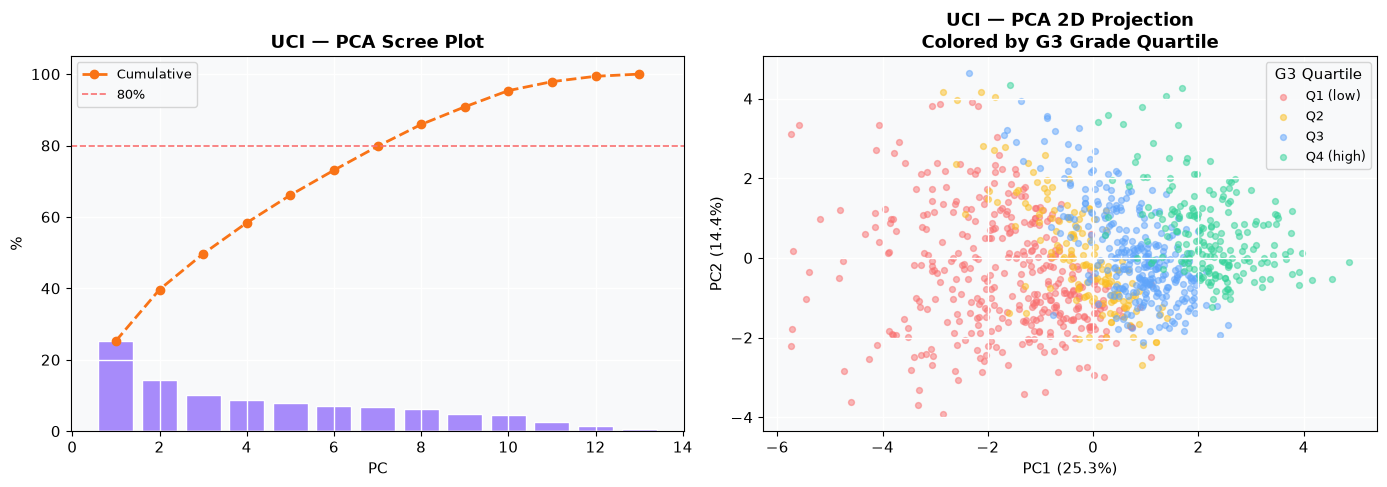

In [18]:
X_uc = df_uc[UCI_FEATURES].dropna()
scaler_uc = StandardScaler()
X_uc_scaled = scaler_uc.fit_transform(X_uc)

pca_uc = PCA(n_components=2)
scores_uc = pca_uc.fit_transform(X_uc_scaled)

# Color by G3 performance quartile
g3_quartile = pd.qcut(df_uc.loc[X_uc.index, "g3"], q=4,
                       labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
uc_palette  = {"Q1 (low)":"#f87171","Q2":"#fbbf24","Q3":"#60a5fa","Q4 (high)":"#34d399"}

pca_uc_full = PCA()
ev_uc = pca_uc_full.fit(X_uc_scaled).explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree
axes[0].bar(range(1,len(ev_uc)+1), ev_uc*100, color="#a78bfa", edgecolor="white")
axes[0].plot(range(1,len(ev_uc)+1), np.cumsum(ev_uc)*100, "o--", color="#f97316",
             linewidth=2, label="Cumulative")
axes[0].axhline(80, color="#f87171", linestyle="--", linewidth=1.2, label="80%")
axes[0].set_title("UCI — PCA Scree Plot", fontweight="bold")
axes[0].set_xlabel("PC")
axes[0].set_ylabel("%")
axes[0].legend(fontsize=9)

# 2D scores colored by G3 quartile
for label in ["Q1 (low)","Q2","Q3","Q4 (high)"]:
    mask = g3_quartile == label
    axes[1].scatter(scores_uc[mask,0], scores_uc[mask,1],
                    c=uc_palette[label], label=label, alpha=0.5, s=18)
axes[1].set_xlabel(f"PC1 ({pca_uc.explained_variance_ratio_[0]*100:.1f}%)", fontsize=11)
axes[1].set_ylabel(f"PC2 ({pca_uc.explained_variance_ratio_[1]*100:.1f}%)", fontsize=11)
axes[1].set_title("UCI — PCA 2D Projection\nColored by G3 Grade Quartile", fontweight="bold")
axes[1].legend(title="G3 Quartile", fontsize=9)

plt.tight_layout()
plt.savefig("data/analytics/uci_pca.png", dpi=130, bbox_inches="tight")
plt.show()


---
## 5 · t-SNE — Non-Linear Dimensionality Reduction

**What t-SNE does:**  
t-SNE (t-distributed Stochastic Neighbor Embedding) is fundamentally different from PCA. Instead of maximizing variance in a linear projection, t-SNE tries to **preserve local neighbourhood structure** — points that are close together in the high-dimensional space are placed close together in 2D.

**PCA vs t-SNE — when to use which:**

| | PCA | t-SNE |
|--|-----|-------|
| Type | Linear | Non-linear |
| What it preserves | Global variance | Local neighbourhoods |
| Result is reproducible | Yes | No (random init, use `random_state`) |
| Good for | Seeing global structure, feature loadings | Seeing cluster shapes |
| Axes are interpretable | Yes (variance explained) | **No** — axis values are meaningless |
| Fast? | Yes | Slow for large n (sub-sample if >5000 rows) |

**Important:** t-SNE axes have **no intrinsic meaning**. You cannot say "PC1 direction means more stress". You can only interpret the relative positions and cluster shapes of the points.

**Hyperparameter — perplexity:** Controls how many neighbours each point considers. Typical range 5–50. A higher perplexity makes t-SNE focus on more global structure; lower = more local. Always test 2–3 values.


In [21]:
# Sub-sample for speed (t-SNE is O(n²) → slow on 2000 rows in a notebook)
np.random.seed(42)
n_sample = min(800, len(X_ls_scaled))
idx = np.random.choice(len(X_ls_scaled), size=n_sample, replace=False)
X_tsne_input  = X_ls_scaled[idx]
stress_sample = stress_aligned.iloc[idx]

print(f"Running t-SNE on {n_sample} students (sub-sampled for speed)...")
print("Perplexity = 30  |  n_iter = 1000  |  random_state = 42")

tsne = TSNE(n_components=2, perplexity=30, n_iter_without_progress=1000,
            random_state=42, learning_rate="auto", init="pca")
embed = tsne.fit_transform(X_tsne_input)

print(f"Done. Embedding shape: {embed.shape}")
print(f"KL divergence (lower = better fit): {tsne.kl_divergence_:.4f}")


Running t-SNE on 800 students (sub-sampled for speed)...
Perplexity = 30  |  n_iter = 1000  |  random_state = 42
Done. Embedding shape: (800, 2)
KL divergence (lower = better fit): 1.0628


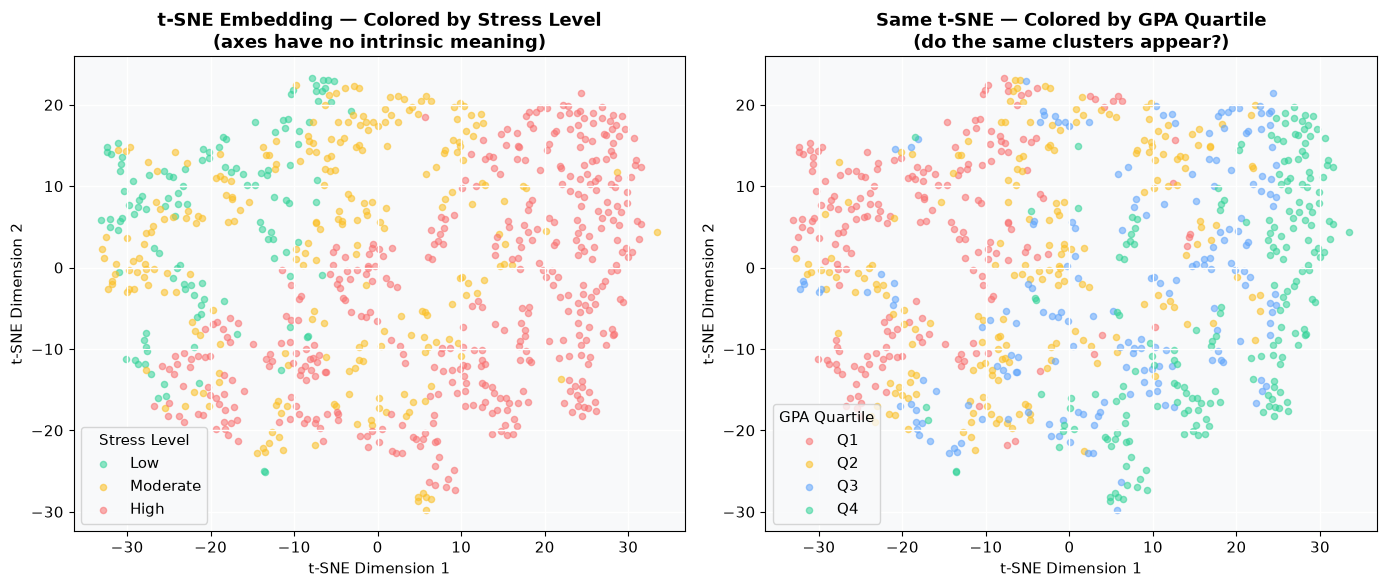


Key insight: If the same clusters appear in BOTH colorings,
it means stress level and GPA co-vary in the same student groups.


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# t-SNE colored by stress level
for level in ["Low", "Moderate", "High"]:
    mask = stress_sample.values == level
    axes[0].scatter(embed[mask,0], embed[mask,1],
                    c=PALETTE[level], label=level, alpha=0.55, s=20)
axes[0].set_title("t-SNE Embedding — Colored by Stress Level\n"
                  "(axes have no intrinsic meaning)", fontweight="bold")
axes[0].set_xlabel("t-SNE Dimension 1")
axes[0].set_ylabel("t-SNE Dimension 2")
axes[0].legend(title="Stress Level")

# Same t-SNE colored by GPA quartile
gpa_sample = df_ls.loc[X_ls.index, "gpa"].iloc[idx]
gpa_q = pd.qcut(gpa_sample, q=4, labels=["Q1","Q2","Q3","Q4"])
gpa_palette = {"Q1":"#f87171","Q2":"#fbbf24","Q3":"#60a5fa","Q4":"#34d399"}
for q in ["Q1","Q2","Q3","Q4"]:
    mask = gpa_q.values == q
    axes[1].scatter(embed[mask,0], embed[mask,1],
                    c=gpa_palette[q], label=q, alpha=0.55, s=20)
axes[1].set_title("Same t-SNE — Colored by GPA Quartile\n"
                  "(do the same clusters appear?)", fontweight="bold")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
axes[1].legend(title="GPA Quartile")

plt.tight_layout()
plt.savefig("data/analytics/ls_tsne.png", dpi=130, bbox_inches="tight")
plt.show()

print("\nKey insight: If the same clusters appear in BOTH colorings,")
print("it means stress level and GPA co-vary in the same student groups.")


---
## 6 · Feature Importance — Mutual Information

**Why not just use correlation for feature importance?**  
Pearson's r only captures **linear** relationships. If a feature has a non-linear (e.g. U-shaped) relationship with the target, Pearson gives r ≈ 0 — even though the feature is informative!

**Mutual Information (MI)** measures the general statistical dependence between two variables, regardless of whether the relationship is linear. It comes from information theory:  
- MI = 0: the feature tells you **nothing** about the target  
- MI > 0: knowing the feature **reduces uncertainty** about the target  
- MI has no maximum (unlike r which is bounded −1 to +1)

**Practical use:** MI is used as a **filter-based feature selection** method — rank features by MI with the target and keep the top-k. This is done *before* fitting any model.


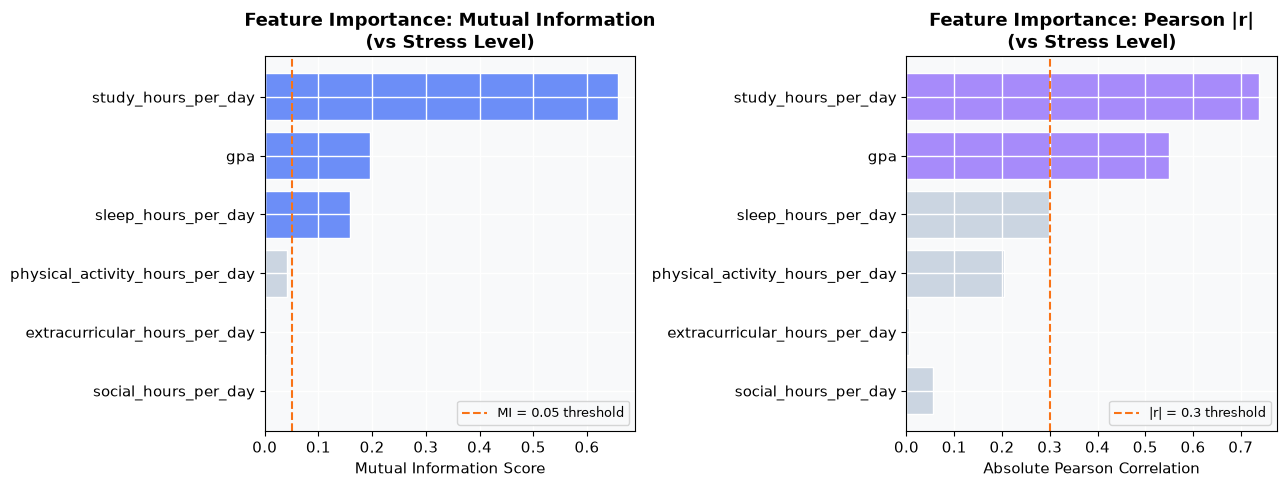

=== Feature Importance Comparison ===
                                 Mutual_Info  Pearson_r_abs  MI_rank  Pearson_rank
study_hours_per_day                   0.6570         0.7388        1             1
gpa                                   0.1961         0.5504        2             2
sleep_hours_per_day                   0.1590         0.2989        3             3
physical_activity_hours_per_day       0.0421         0.2052        4             4
extracurricular_hours_per_day         0.0034         0.0061        5             6
social_hours_per_day                  0.0000         0.0547        6             5

→ When MI rank and Pearson rank disagree, non-linear relationships exist.


In [23]:
from sklearn.feature_selection import mutual_info_classif

# Encode stress as integer label
le = LabelEncoder()
y_ls = le.fit_transform(df_ls.loc[X_ls.index, "stress_level"])

# Compute MI for each feature vs stress label
mi_scores = mutual_info_classif(X_ls_scaled, y_ls, random_state=42)
mi_series = pd.Series(mi_scores, index=LS_FEATURES).sort_values(ascending=False)

# Also compute absolute Pearson r for comparison
stress_num = df_ls.loc[X_ls.index, "stress_level"].map({"Low":0,"Moderate":1,"High":2})
pearson_r  = X_ls.corrwith(stress_num).abs().reindex(mi_series.index)

# ── Plot comparison: MI vs Pearson |r| ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mutual Information
colors_mi = ["#6c8ef7" if s >= 0.05 else "#cbd5e1" for s in mi_series.values]
axes[0].barh(mi_series.index[::-1], mi_series.values[::-1],
             color=colors_mi[::-1], edgecolor="white")
axes[0].axvline(0.05, color="#f97316", linestyle="--",
                linewidth=1.5, label="MI = 0.05 threshold")
axes[0].set_title("Feature Importance: Mutual Information\n(vs Stress Level)", fontweight="bold")
axes[0].set_xlabel("Mutual Information Score")
axes[0].legend(fontsize=9)

# Pearson |r|
colors_p = ["#a78bfa" if r >= 0.3 else "#cbd5e1" for r in pearson_r.values]
axes[1].barh(pearson_r.index[::-1], pearson_r.values[::-1],
             color=colors_p[::-1], edgecolor="white")
axes[1].axvline(0.3, color="#f97316", linestyle="--",
                linewidth=1.5, label="|r| = 0.3 threshold")
axes[1].set_title("Feature Importance: Pearson |r|\n(vs Stress Level)", fontweight="bold")
axes[1].set_xlabel("Absolute Pearson Correlation")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig("data/analytics/ls_mutual_information.png", dpi=130, bbox_inches="tight")
plt.show()

print("=== Feature Importance Comparison ===")
comparison = pd.DataFrame({"Mutual_Info": mi_series, "Pearson_r_abs": pearson_r})
comparison["MI_rank"] = comparison["Mutual_Info"].rank(ascending=False).astype(int)
comparison["Pearson_rank"] = comparison["Pearson_r_abs"].rank(ascending=False).astype(int)
print(comparison.round(4).to_string())
print("\n→ When MI rank and Pearson rank disagree, non-linear relationships exist.")


---
## 7 · K-Means Clustering

**What K-Means does:**  
K-Means partitions students into K groups (clusters) such that students within a cluster are similar to each other and different from students in other clusters. "Similarity" is measured as **Euclidean distance** in the feature space.

**How it works (intuition):**  
1. Place K random centroids in the feature space  
2. Assign each student to their nearest centroid  
3. Move each centroid to the mean of its assigned students  
4. Repeat until assignments stop changing  

**How to choose K:**  
Two complementary methods are used here:  
- **Elbow Method:** Plot Within-Cluster Sum of Squares (WCSS) vs K. The "elbow" point where improvement slows is the optimal K.  
- **Silhouette Score:** Measures how well each point fits its own cluster vs the nearest other cluster. Ranges −1 to +1; higher is better. The K with the highest silhouette score is optimal.

**Important:** Always run K-Means on **standardized** features (same scaler from PCA). Without standardization, features with larger scales dominate the distance calculation.


### 7.1 · Elbow Method + Silhouette Analysis

In [24]:
wcss_values = []
sil_values  = []
K_range     = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_ls_scaled)
    wcss_values.append(km.inertia_)
    sil_values.append(silhouette_score(X_ls_scaled, labels))
    print(f"  K={k}  WCSS={km.inertia_:,.0f}  Silhouette={sil_values[-1]:.4f}")

# Find elbow using rate-of-change
wcss_arr   = np.array(wcss_values)
delta      = np.diff(wcss_arr)
delta2     = np.diff(delta)         # second derivative — maximum = elbow
elbow_k    = list(K_range)[np.argmax(delta2) + 1]
best_sil_k = list(K_range)[np.argmax(sil_values)]

print(f"\n→ Elbow method suggests K = {elbow_k}")
print(f"→ Best silhouette score at K = {best_sil_k}  (score={max(sil_values):.4f})")


  K=2  WCSS=9,024  Silhouette=0.2225
  K=3  WCSS=7,592  Silhouette=0.2060
  K=4  WCSS=6,646  Silhouette=0.2041
  K=5  WCSS=6,094  Silhouette=0.1932
  K=6  WCSS=5,583  Silhouette=0.1887
  K=7  WCSS=5,138  Silhouette=0.1970
  K=8  WCSS=4,783  Silhouette=0.2002
  K=9  WCSS=4,479  Silhouette=0.2033

→ Elbow method suggests K = 3
→ Best silhouette score at K = 2  (score=0.2225)


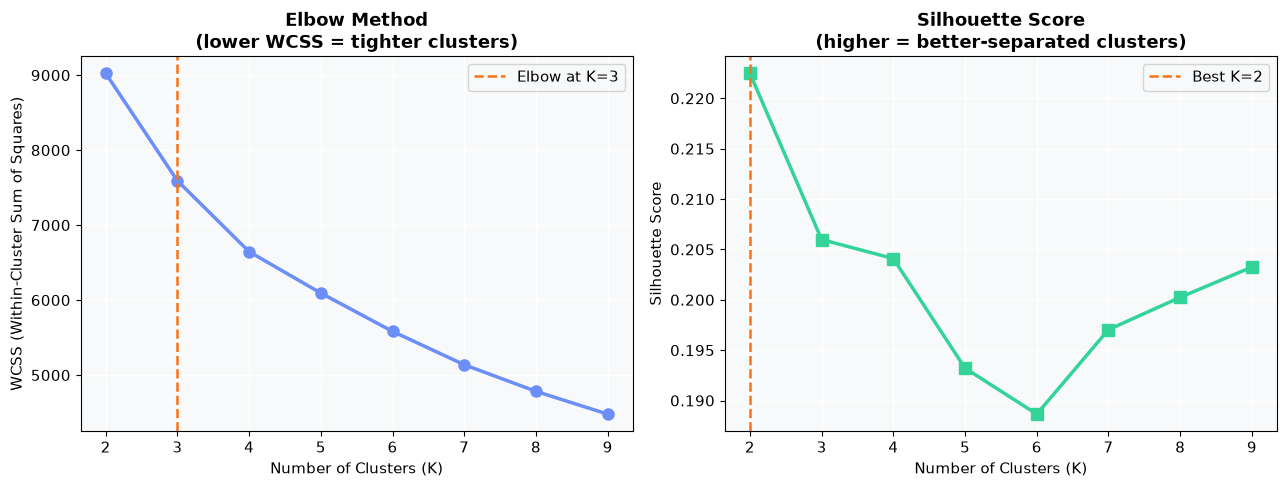

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow plot
axes[0].plot(list(K_range), wcss_values, "o-", color="#6c8ef7",
             linewidth=2.5, markersize=8)
axes[0].axvline(elbow_k, color="#f97316", linestyle="--",
                linewidth=1.8, label=f"Elbow at K={elbow_k}")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS (Within-Cluster Sum of Squares)")
axes[0].set_title("Elbow Method\n(lower WCSS = tighter clusters)", fontweight="bold")
axes[0].legend()

# Silhouette score
axes[1].plot(list(K_range), sil_values, "s-", color="#34d399",
             linewidth=2.5, markersize=8)
axes[1].axvline(best_sil_k, color="#f97316", linestyle="--",
                linewidth=1.8, label=f"Best K={best_sil_k}")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score\n(higher = better-separated clusters)", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig("data/analytics/ls_kmeans_selection.png", dpi=130, bbox_inches="tight")
plt.show()


### 7.2 · Fit Final K-Means and Profile the Clusters

In [26]:
# Use K from silhouette analysis (or override manually)
BEST_K = best_sil_k

km_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
df_ls_clustered = df_ls.loc[X_ls.index].copy()
df_ls_clustered["cluster"] = km_final.fit_predict(X_ls_scaled)

print(f"Cluster sizes (K={BEST_K}):")
print(df_ls_clustered["cluster"].value_counts().sort_index())


Cluster sizes (K=2):
cluster
0     973
1    1027
Name: count, dtype: int64


In [27]:
# ── Cluster profiles — mean feature value per cluster ────────────────────────
profile_cols = LS_FEATURES + ["stress_level"]
cluster_means = df_ls_clustered.groupby("cluster")[LS_FEATURES].mean().round(3)

print("=== Cluster Mean Feature Values ===")
print(cluster_means.T.to_string())


=== Cluster Mean Feature Values ===
cluster                              0      1
study_hours_per_day              8.635  6.377
sleep_hours_per_day              7.795  7.223
extracurricular_hours_per_day    2.114  1.873
social_hours_per_day             2.653  2.754
physical_activity_hours_per_day  2.804  5.773
gpa                              3.324  2.919


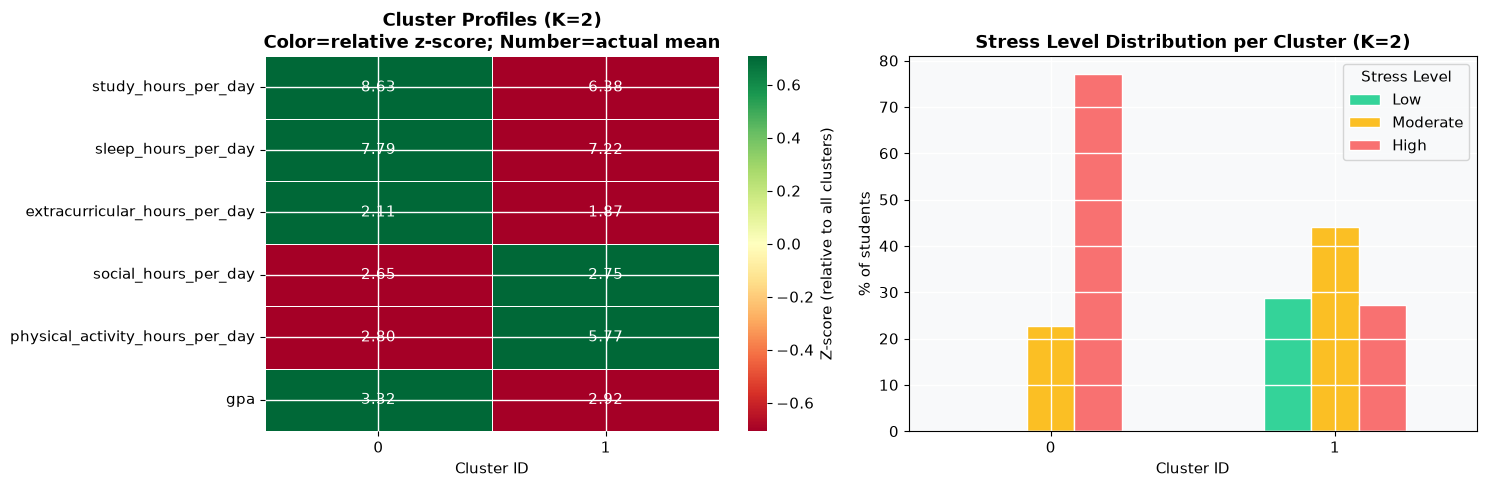

In [28]:
# ── Heatmap of cluster profiles ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Z-scored means for heatmap (easier to read relative differences)
cluster_means_z = (cluster_means - cluster_means.mean()) / cluster_means.std()
sns.heatmap(cluster_means_z.T, annot=cluster_means.T, fmt=".2f",
            cmap="RdYlGn", center=0, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Z-score (relative to all clusters)"},
            ax=axes[0])
axes[0].set_title(f"Cluster Profiles (K={BEST_K})\n"
                  "Color=relative z-score; Number=actual mean", fontweight="bold")
axes[0].set_xlabel("Cluster ID")

# Stress level distribution per cluster
stress_cluster = df_ls_clustered.groupby(["cluster","stress_level"]).size().unstack(fill_value=0)
stress_cluster_pct = stress_cluster.div(stress_cluster.sum(axis=1), axis=0) * 100

stress_cluster_pct[["Low","Moderate","High"]].plot(
    kind="bar", color=["#34d399","#fbbf24","#f87171"],
    edgecolor="white", ax=axes[1]
)
axes[1].set_title(f"Stress Level Distribution per Cluster (K={BEST_K})",
                  fontweight="bold")
axes[1].set_xlabel("Cluster ID")
axes[1].set_ylabel("% of students")
axes[1].legend(title="Stress Level")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("data/analytics/ls_cluster_profiles.png", dpi=130, bbox_inches="tight")
plt.show()


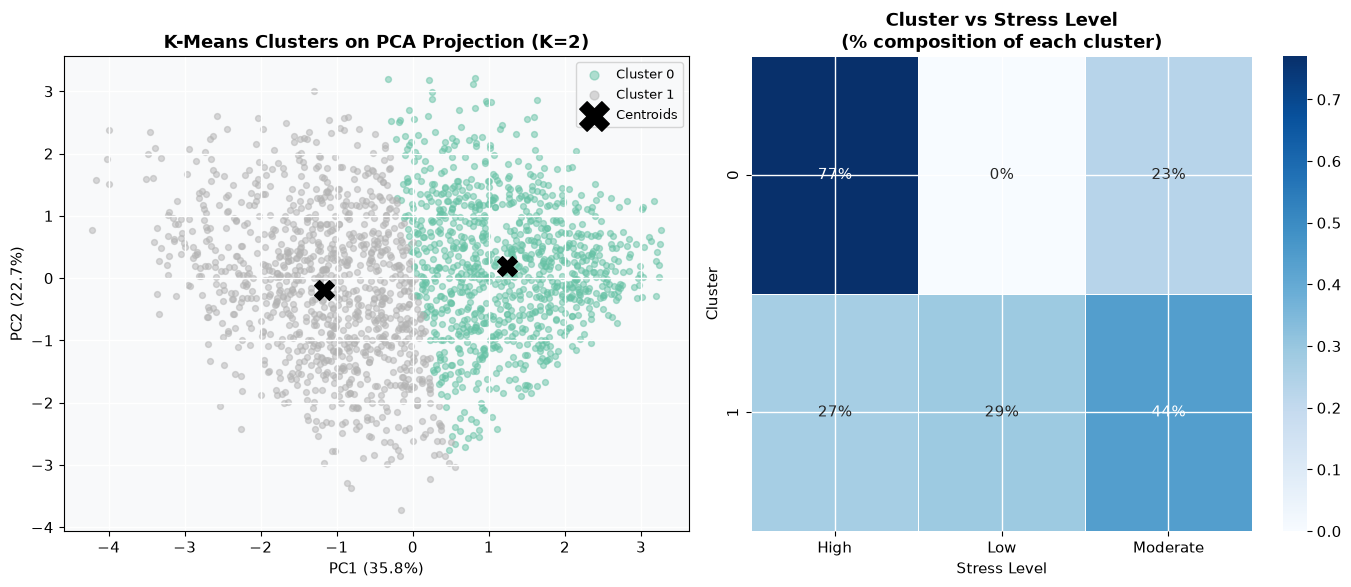

In [29]:
# ── Visualize clusters on PCA 2D projection ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cluster_colors = plt.cm.Set2(np.linspace(0, 1, BEST_K))

for k in range(BEST_K):
    mask = df_ls_clustered["cluster"] == k
    axes[0].scatter(scores[mask, 0], scores[mask, 1],
                    c=[cluster_colors[k]], label=f"Cluster {k}",
                    alpha=0.5, s=18)
# Plot centroids projected onto PCA space
centroids_pca = pca_ls.transform(km_final.cluster_centers_)
axes[0].scatter(centroids_pca[:,0], centroids_pca[:,1],
                marker="X", s=200, c="black", zorder=5, label="Centroids")
axes[0].set_xlabel(f"PC1 ({pca_ls.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca_ls.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title(f"K-Means Clusters on PCA Projection (K={BEST_K})", fontweight="bold")
axes[0].legend(markerscale=1.5, fontsize=9)

# Compare clusters vs stress (contingency heatmap)
ct = pd.crosstab(df_ls_clustered["cluster"],
                 df_ls_clustered["stress_level"])
ct_pct = ct.div(ct.sum(axis=1), axis=0).round(2)
sns.heatmap(ct_pct, annot=True, fmt=".0%", cmap="Blues",
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_title("Cluster vs Stress Level\n(% composition of each cluster)",
                  fontweight="bold")
axes[1].set_xlabel("Stress Level")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.savefig("data/analytics/ls_cluster_pca_vs_stress.png", dpi=130, bbox_inches="tight")
plt.show()


---
## 8 · Cross-Dataset Comparison (Standardized Table)

**What we do here:**  
Build (or load) the standardized table and run comparisons that are **valid across different populations** — using only relative measures like percentile rank, not raw scores.

**Why percentile rank:**  
A student in the 80th percentile means the same thing regardless of whether the underlying scale was 0–4 or 0–20. Percentile rank transforms any scale into a universal 0–100 comparison axis.

**What to look for:**  
- Do stress groups show the same academic performance pattern across all three datasets?  
- Is the academic–stress relationship consistent across populations, or is it population-specific?


In [30]:
from scipy.stats import percentileofscore

def add_percentile(df, score_col):
    scores = df[score_col].dropna().values
    def pct(x):
        return percentileofscore(scores, x, kind="rank") if pd.notna(x) else np.nan
    df = df.copy()
    df["academic_percentile"] = df[score_col].apply(pct)
    return df

# Add percentile to each dataset
df_ls_p = add_percentile(df_ls, "gpa")
df_uc_p = add_percentile(df_uc, "g3")
df_mh_p = add_percentile(df_mh, "cgpa_midpoint")

# Encode stress label for Mental Health and UCI using derived columns
df_uc_p["stress_level_for_plot"] = df_uc_p.get("stress_label_proxy", "Unknown")
df_mh_p["stress_level_for_plot"] = df_mh_p.get("stress_label", "Unknown")
df_ls_p["stress_level_for_plot"] = df_ls_p["stress_level"]

# Build minimal standardized table
std_ls = pd.DataFrame({
    "source_dataset": "lifestyle",
    "academic_percentile": df_ls_p["academic_percentile"],
    "stress_label": df_ls_p["stress_level_for_plot"],
})
std_uc = pd.DataFrame({
    "source_dataset": "uci",
    "academic_percentile": df_uc_p["academic_percentile"],
    "stress_label": df_uc_p["stress_level_for_plot"],
})
std_mh = pd.DataFrame({
    "source_dataset": "mental_health",
    "academic_percentile": df_mh_p["academic_percentile"],
    "stress_label": df_mh_p["stress_level_for_plot"],
})

std = pd.concat([std_ls, std_uc, std_mh], ignore_index=True)
std = std[std["stress_label"].isin(["Low","Moderate","High"])]

print(f"Standardized table shape: {std.shape}")
print(std.groupby("source_dataset")["academic_percentile"].describe().round(2))

std.to_csv("data/analytics/standardized_students.csv", index=False)
print("\n✅ Saved standardized_students.csv")


Standardized table shape: (3144, 3)
                 count   mean    std   min    25%    50%    75%    max
source_dataset                                                        
lifestyle       2000.0  50.02  28.87  0.05  25.18  49.98  75.28  100.0
mental_health    100.0  50.50  26.11  2.00  31.00  31.00  76.50   76.5
uci             1044.0  50.05  28.73  2.59  29.41  43.97  76.20  100.0

✅ Saved standardized_students.csv


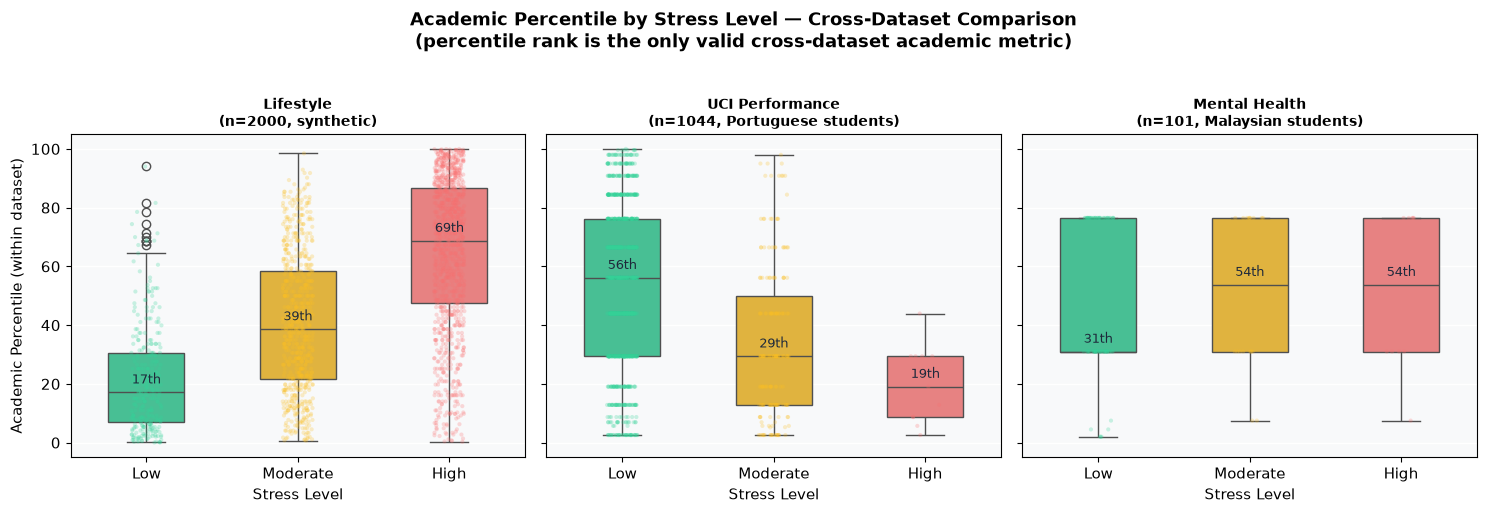

In [31]:
# ── Faceted box plot: academic percentile by stress, per dataset ──────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

dataset_labels = {
    "lifestyle":    "Lifestyle\n(n=2000, synthetic)",
    "uci":          "UCI Performance\n(n=1044, Portuguese students)",
    "mental_health":"Mental Health\n(n=101, Malaysian students)"
}

for ax, ds in zip(axes, ["lifestyle", "uci", "mental_health"]):
    subset = std[std["source_dataset"] == ds]
    order  = ["Low", "Moderate", "High"]
    order  = [o for o in order if o in subset["stress_label"].unique()]

    sns.boxplot(data=subset, x="stress_label", y="academic_percentile",
                order=order, palette=PALETTE,
                width=0.5, ax=ax)
    sns.stripplot(data=subset, x="stress_label", y="academic_percentile",
                  order=order, palette=PALETTE,
                  alpha=0.25, size=3, jitter=True, ax=ax)

    ax.set_title(dataset_labels[ds], fontweight="bold", fontsize=10)
    ax.set_xlabel("Stress Level")
    ax.set_ylabel("Academic Percentile (within dataset)" if ax == axes[0] else "")

    # Add median annotations
    for i, level in enumerate(order):
        med = subset[subset["stress_label"]==level]["academic_percentile"].median()
        ax.text(i, med + 3, f"{med:.0f}th", ha="center", fontsize=9, color="#1e293b")

plt.suptitle("Academic Percentile by Stress Level — Cross-Dataset Comparison\n"
             "(percentile rank is the only valid cross-dataset academic metric)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("data/analytics/cross_dataset_comparison.png", dpi=130, bbox_inches="tight")
plt.show()


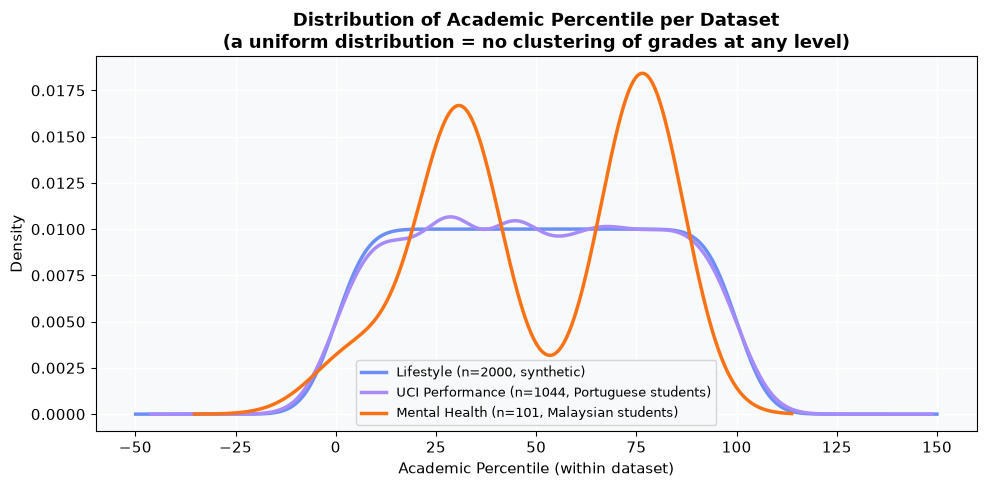

Interpretation:
  A KDE curve near-flat = grades are evenly spread (uniform)
  A peaked KDE = grades cluster around a specific level


In [32]:
# ── KDE of academic percentile per dataset (overall distribution shape) ─────
fig, ax = plt.subplots(figsize=(10, 5))

for ds, color in DS_PALETTE.items():
    subset = std[std["source_dataset"] == ds]["academic_percentile"].dropna()
    subset.plot.kde(ax=ax, label=dataset_labels[ds].replace("\n"," "),
                    color=color, linewidth=2.5)

ax.set_xlabel("Academic Percentile (within dataset)")
ax.set_ylabel("Density")
ax.set_title("Distribution of Academic Percentile per Dataset\n"
             "(a uniform distribution = no clustering of grades at any level)",
             fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("data/analytics/cross_dataset_kde.png", dpi=130, bbox_inches="tight")
plt.show()

print("Interpretation:")
print("  A KDE curve near-flat = grades are evenly spread (uniform)")
print("  A peaked KDE = grades cluster around a specific level")


---
## 9 · Analytics Summary

### Techniques Used — Quick Reference for Your Viva

| Technique | What it answers | Key result to report |
|-----------|----------------|---------------------|
| **Correlation heatmap** | Which features are linearly related? | r values, multicollinearity in G1/G2/G3 |
| **Point-biserial / Phi** | Binary ↔ continuous / binary ↔ binary relationships | Significance of depression↔CGPA link |
| **Violin + KDE plots** | How do distributions differ by stress group? | Overlap = weak discriminator; separation = strong |
| **IQR outlier detection** | Which rows are extreme values? | Count, location, whether to keep/flag/remove |
| **Z-score outliers** | Same, but using standard deviations | Complements IQR for normal distributions |
| **PCA — Scree plot** | How many components are needed? | Number of PCs for 80%/95% variance |
| **PCA — Biplot** | What does each PC mean semantically? | Feature loadings on PC1, PC2 |
| **t-SNE** | Are there natural student clusters? | Cluster shapes, colour consistency |
| **Mutual Information** | Which features are informative (incl. non-linear)? | MI ranking vs Pearson ranking |
| **K-Means — Elbow** | How many natural groups exist? | WCSS elbow point |
| **K-Means — Silhouette** | How well-separated are the clusters? | Best K by silhouette score |
| **Cluster profiles** | What characterises each student group? | Mean feature values per cluster |
| **Cross-dataset boxes** | Do stress groups differ academically across populations? | Median percentile per stress level per dataset |

### Key Analytical Decisions Made

1. **Standardization before PCA/K-Means** — mandatory to prevent scale-dominant features  
2. **Sub-sampling for t-SNE** — t-SNE is O(n²); 800 rows is sufficient for pattern discovery  
3. **Mutual Information over Pearson for ranking** — captures non-linear relationships  
4. **Percentile rank for cross-dataset comparison** — the only valid common academic metric  
5. **Derived stress proxies labelled** — never presented as self-reported stress


In [33]:
print("=== Final Outputs in data/analytics/ ===")
import os
for f in sorted(os.listdir("data/analytics")):
    size = os.path.getsize(f"data/analytics/{f}")
    print(f"  {f:<45} {size/1024:.1f} KB")


=== Final Outputs in data/analytics/ ===
  cross_dataset_comparison.png                  157.1 KB
  cross_dataset_kde.png                         86.8 KB
  ls_cluster_pca_vs_stress.png                  231.9 KB
  ls_cluster_profiles.png                       86.7 KB
  ls_correlation_heatmap.png                    94.1 KB
  ls_kde_study_gpa.png                          113.5 KB
  ls_kmeans_selection.png                       94.5 KB
  ls_mutual_information.png                     78.8 KB
  ls_outlier_boxplots.png                       92.6 KB
  ls_pca_biplot.png                             242.2 KB
  ls_pca_scree.png                              89.3 KB
  ls_tsne.png                                   205.4 KB
  ls_violin_by_stress.png                       324.0 KB
  standardized_students.csv                     86.6 KB
  uci_correlation_heatmap.png                   190.2 KB
  uci_grade_progression.png                     62.8 KB
  uci_pca.png                                   164.4 KB